# 02 · Predictors and memory at 100 m

**Question:** can the platform's land-use predictors be built at 100 m, and how much time and memory does the platform's own run take at 100 m?

Both are answered with the platform's `main` branch (commit 6710b3d, 28 October 2026). Its `landuse_tool` is copied read-only into `data/platform_main` (git archive, not edited) and run unchanged on files written on the 100 m grid. Nothing is fetched from Earth Engine. Computations are in `scripts/predictors_lu100.py` and `scripts/platform100.py`; inputs and runs are on `E:\SDG AI Lab\Guinea\data_100m\landuse\`.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import predictors_lu100 as P
import classes100 as C
G, H = C.G, C.H

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 80)
OUT = Path.cwd().parent / "outputs"
RUN = P.LANDUSE / "runs" / "test_s42"

## 1 · What the platform runs on `main`

Read from `backend/landuse_api/tasks.py` (`run_training`, `run_prediction`) and `landuse_tool` (`training.py`, `prediction.py`, `change_analysis.py`, `config.py`):

| Part | On `main` |
|---|---|
| Label | Esri land cover read at 100 m and clipped to Guinea; clouds are kept as a class |
| Transitions | Every transition with a count above zero between the first and last training year; a transition with fewer than 10 samples gets no model |
| Model | One Random Forest per transition (100 trees, depth 20, `random_state` 42), up to 50,000 changed and 50,000 unchanged cells drawn at random; `use_growth_modes=False` by default, so no Expander/Patcher split |
| Predictors | The 12 of `LAND_USE_PREDICTOR_RASTERS` / `_VECTORS` (section 2), dated to the first training year; held together in memory, then written one file each |
| Suitability | The model's probability for every cell of the transition's start class, with the base year's predictors |
| Demand | `run_change_analysis` on every Esri year from 2017 to the base year (a fitted trend with four or more maps), times the number of years ahead |
| Allocation | Transitions in order of demand, largest first; each takes the highest-suitability cells still in its start class. No neighbourhood, no radius |

At 100 m, notebook 04 scores the platform's run as it is on `main`, and the improvements are compared against it.

## 2 · The predictors

Each predictor is made as `main` makes it, from the files the platform fetched for the 250 m experiments (coarse sources) or the shared 100 m store (sources at 100 m or finer). Coarse sources are read by nearest neighbour, as Earth Engine reads a coarser image at a finer scale (Google Earth Engine, *Scale* guide). Agreement is the Spearman correlation with the same predictor in the 250 m experiments, at the 250 m pixel of each 100 m cell (400,000 cells drawn at random), for 2023.

In [2]:
timings = {}
X = P.stack(2023, timings=timings)
del X
agree = P.agreement_with_250m(2023)
agree["build (s)"] = [timings[f] for f in agree.file]
source = {"DEM_GEE": "SRTM, read at 100 m", "POPULATION_DENSITY": "WorldPop, read at 100 m",
          "PRECIPITATION": "CHIRPS annual total (0.05°)", "SOIL_MOISTURE": "ERA5-Land annual mean (0.1°)",
          "AGB_NASA": "NASA/ORNL biomass 2010 (300 m)", "NDVI": "MOD13Q1 annual mean (250 m)",
          "SLOPE": "From the DEM (platform's function)", "ASPECT": "From the DEM (platform's function)",
          "ROADS_distance": "OpenStreetMap highways, distance in cells", "WATERWAYS_distance": "OpenStreetMap waterways and water, distance in cells",
          "POI_heatmap": "OpenStreetMap amenities, decay with distance", "PROTECTED_AREAS_zone": "WDPA, inside or not"}
agree.insert(1, "source", agree.file.map(source))
C.save("02_predictors.csv", agree)
agree.drop(columns="file").round(3)

,source,year used,no value (% of cells),Spearman with 250 m,build (s)
predictor,,,,,
Elevation,"SRTM, read at 100 m",static,0.0,0.998,4.427
Population density,"WorldPop, read at 100 m",2020,0.0,0.962,0.710
Precipitation,CHIRPS annual total (0.05°),2023,0.0,0.995,1.517
Soil moisture,ERA5-Land annual mean (0.1°),2023,0.0,0.981,1.406
Above-ground biomass,NASA/ORNL biomass 2010 (300 m),2010,0.0,0.909,1.192
NDVI,MOD13Q1 annual mean (250 m),2023,0.0,0.980,1.443
Slope,From the DEM (platform's function),static,0.0,0.756,2.748
Aspect,From the DEM (platform's function),static,0.0,0.479,3.994
Distance to roads,"OpenStreetMap highways, distance in cells",static,0.0,0.674,4.838


**Reading:**

* **All 12 predictors build from local files in about 30 s**, with a value in every cell inside Guinea.
* **Same source, same values:** elevation, rainfall, soil moisture, NDVI, protected areas and distance to waterways agree with the 250 m layers at 0.97–1.00, population at 0.96 and biomass at 0.91 (its 300 m pixels are read differently on the two grids).
* **Slope (0.76) and aspect (0.48) are sharper at 100 m**, as in the deforestation work: a 250 m cell averages out small valleys.
* **Roads (0.67) and points of interest (0.74) differ by OpenStreetMap snapshot:** the 100 m layers use the extract of 27 October 2026 with the platform's tags, the 250 m ones the platform's earlier cache. OpenStreetMap in Guinea is still growing, so newer is closer to what the platform fetches today.
* **Two small differences from the platform, in our copy of the inputs only.** The platform downloads every layer itself at 100 m; nothing here changes that. Here, protected areas are Guinea's designated, inscribed and established areas at cell centres (the platform takes every polygon touching Guinea, with all touched cells). Rainfall (pixels of about 5 km), soil moisture (about 11 km) and NDVI (250 m) are read from the files downloaded with the platform's code for the 250 m experiments instead of being downloaded again; their sources are no finer than 250 m, so the values at 100 m are nearly the same (0.97–1.00 above). Both differences are the same for every method compared.

## 3 · On the map

Three predictors in the 25 km block of notebook 01, on both grids: slope gains most from 100 m, distance to roads changes with the OpenStreetMap snapshot, NDVI is the same source.

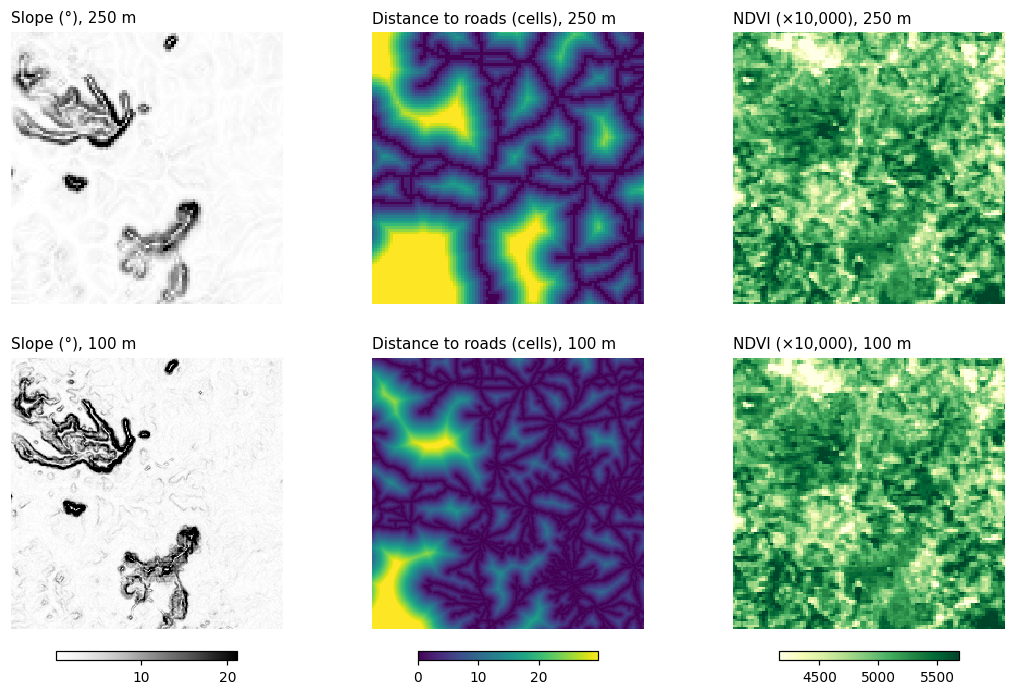

In [3]:
import esri_methods as E
window = C.busiest_window()
maps = C.window_maps(window)
prof250 = E.grid()
s250 = E.predictor_stack(prof250, np.ones((prof250["height"], prof250["width"]), bool), year=2023)
r, c, n = window
ext = maps["250 m extent"]
t, cell, t2 = G.grid()["transform"], G.CELL_DEG, prof250["transform"]
c0 = int(np.floor((t[2] + c * cell - t2.c) / t2.a)); r0 = int(np.floor((t[5] - r * cell - t2.f) / t2.e))
h250, w250 = maps["250 m start"].shape
show = [("SLOPE", "Slope", "Slope (°)", "Greys"), ("ROADS_distance", "Roads (distance)", "Distance to roads (cells)", "viridis"),
        ("NDVI", "NDVI", "NDVI (×10,000)", "YlGn")]
fig, axes = plt.subplots(2, 3, figsize=(12, 8.6))
for j, (name, name250, title, cmap) in enumerate(show):
    v100 = G.to_grid(P.predictor(name, 2023))[r:r + n, c:c + n]
    v250 = s250[E.PREDICTORS.index(name250)][r0:r0 + h250, c0:c0 + w250]
    lo, hi = np.nanpercentile(v100, [2, 98])
    scale = 2.5 if name == "ROADS_distance" else 1.0                  # 250 m cells are 2.5 times larger
    for i, (v, label, e) in enumerate(((v250 * scale, "250 m", ext), (v100, "100 m", (-0.5, n - 0.5, n - 0.5, -0.5)))):
        ax = axes[i, j]
        im = ax.imshow(v, cmap=cmap, vmin=lo, vmax=hi, extent=e, interpolation="nearest")
        ax.set_xlim(-0.5, n - 0.5); ax.set_ylim(n - 0.5, -0.5); ax.set_axis_off()
        ax.set_title(f"{title}, {label}", loc="left", fontsize=10)
    fig.colorbar(im, ax=axes[:, j], shrink=0.6, location="bottom", pad=0.03)
plt.show()

**Reading:** slope shows the valleys at 100 m that 250 m smooths away; NDVI is the same picture at both sizes (one MODIS pixel covers several 100 m cells); distance to roads follows more tracks in the newer OpenStreetMap extract (250 m distances are shown in 100 m cells for comparison).

## 4 · Time and memory of the platform's run

The platform's own functions on the device this notebook was run (12 cores, 15 GB of memory, of which about 5 GB were free), for the test window: trained on 2023 → 2024 with the 2023 predictors, run from the 2024 map with the 2024 predictors to 2025. Peak memory counts this process and its worker processes. The first row holds the predictor stack as `assemble_predictor_stack` does, twelve full-grid layers at once, measured in a separate process. Writing the input files on this device took 2 minutes and 3.0 GB the first time.

In [4]:
res = json.loads((RUN / "result.json").read_text())
stack_mem = json.loads((RUN / "stack_memory.json").read_text())
stages = pd.DataFrame([stack_mem] + [s for s in res["stages"] if not s["stage"].startswith("Write inputs")]).set_index("stage")
stages["minutes"] = stages.seconds / 60
cols = [c for c in ["minutes", "peak_GB", "transitions", "models", "maps", "mode"] if c in stages]
C.save("02_platform_time_memory.csv", stages[cols])
alloc = res["allocation"]
print(f"Transitions trained: {len(res['models'])} of {len(res['transitions'])} with a count above zero; "
      f"demand {alloc['total_demand_px']:,} cells, allocated {alloc['total_allocated_px']:,}, unmet {alloc['total_unmet_px']:,}")
stages[cols].round(2)

Transitions trained: 38 of 45 with a count above zero; demand 2,324,062 cells, allocated 2,324,032, unmet 30


,minutes,peak_GB,transitions,models,maps,mode
stage,,,,,,
Predictor stack in memory (assemble_predictor_stack),0.45,5.27,NaN,NaN,NaN,NaN
Training transitions (change analysis),0.15,1.13,45.0,NaN,NaN,NaN
Training (train_transition_models),5.48,3.31,NaN,38.0,NaN,NaN
Suitability atlas (generate_suitability_atlas),7.74,3.39,NaN,NaN,38.0,NaN
Demand (change analysis 2017 to base year),1.19,1.17,NaN,NaN,NaN,Non-Linear Trend
Allocation (run_allocation_simulation),0.84,1.29,NaN,NaN,NaN,NaN


**Reading:**

* **The platform's run takes about 15 minutes per window at 100 m on this device:** 5.5 minutes to train 38 models, 7.7 to score every cell of each start class, 1.2 for the demand and under a minute to allocate.
* **Its stages peak at 3.4 GB**, so the run fits on this laptop and the model notebooks (04–07) can run here one window at a time.
* **Holding the twelve predictors together takes 5.3 GB on its own**, more than any later stage. The platform's code warns of it (`prepare_predictor_files`: "at 100 m country scale that is a few GB"). On the server this comes on top of the Earth Engine downloads and the worker itself, under a limit of about 10 GB, so it is the likeliest reason two of the platform's land-use prediction jobs at 100 m were stopped for running out of memory. Writing each layer to its file as soon as it is made, which is what training and scoring read anyway, would keep this stage to about one layer and its distance calculation at a time (an estimate, not measured here).
* **7 of the 45 transitions get no model** (fewer than 10 samples). Their demand, 30 cells, is reported as unmet. Clouds are treated as a land-cover class: the platform trains, projects and allocates change into and out of clouds. The deployed notebook left them out, and so does the improved method (notebook 06).
* **The projected demand is about a quarter below the change in Esri's maps:** 2.32 million cells for 2024 → 2025 (about 23,000 km²), against the 31,153 km² that changed between Esri's 2024 and 2025 maps (notebook 01). The projection extends the trend of 2017–2024; in 2025 Esri's map changed more than that trend. Notebook 04 scores the run both with this demand, as users get it, and with the observed amount, to compare where methods place change.

## 5 · What this means

* **The platform's own code runs at 100 m here** in about 15 minutes and under 3.5 GB per window. Notebook 04's three seeds on three windows take about 2.5 hours.
* **For the server, the step to change is the predictor stack held in memory** (5.3 GB): a suggestion for the platform, in the README's file.
* **The deployed method at 100 m is the platform's backend:** one Random Forest per transition, no growth modes, no neighbourhood layer, every transition that occurs. Notebook 04 scores it with the observed and the projected amounts, and checks two of its choices: the deployed notebook's 1,000-pixel rule, and clouds kept as a class.
* **Next:** notebook 03 (class areas from the shares), then notebook 04, the deployed method as `main` runs it, on validation (2023 → 2024), test (2024 → 2025) and the back-test (2022 → 2023), with three seeds.

**Sources**

* Google Earth Engine. *Scale* (developer guide). developers.google.com/earth-engine/guides/scale
* GEDH platform repository, `main` at commit 6710b3d: `backend/landuse_api/tasks.py`; `landuse_tool/config.py`, `data_loader.py`, `training.py`, `prediction.py`, `change_analysis.py`.